# Bridge: the National Sedge Model with pymc-marketing

The rest of this companion builds a marketing mix model from scratch: adstock, saturation, priors, the PyMC model, and the diagnostics are all written out by hand so you can see every moving part.
This notebook is a bridge, not a replacement.
It re-fits the national Sedge Shoes model the labs use with [`pymc-marketing`](https://www.pymc-marketing.io/), the production library, so you can see how the internals you learned map onto a tool teams actually ship with.

The point is not that one approach is better.
Learn the internals first, so the library is a convenience rather than a black box, then reach for the library in production where it handles the plumbing (scaling, media transforms, contribution accounting, plotting) for you.

In [1]:
import warnings

import numpy as np
import pandas as pd
import pymc_marketing
from pymc_extras.prior import Prior
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import national_aggregate
from mmm_book.sedge import GROUND_TRUTH, TV_COST_PER_GRP, generate_sedge

mmm_style()
warnings.filterwarnings("ignore")
rng = np.random.default_rng(RANDOM_SEED)
print(f"pymc-marketing version: {pymc_marketing.__version__}")

pymc-marketing version: 1.1.0


## The same data - Sedge Shoes, nationally aggregated

We reuse the exact data the from-scratch labs use: the synthetic Sedge panel, collapsed to one national weekly series with `national_aggregate`.
`pymc-marketing` expects a tidy frame with a date column, one column per channel, any control columns, and the target, so we attach a `date` per week and hand it the five media columns, eight further regressors and revenue.
The book keeps three kinds of non-media regressor apart (Chapter 15): the launch indicator is a baseline event, promotion depth a non-media treatment, and log price, distribution, stock, temperature, rainfall and the log category search index are controls.
The library has one slot for all of them, `control_columns`, so all eight go there, each standardised, and its own Fourier terms carry the seasonality.
TV is measured in GRPs and the other four channels in GBP spend, exactly as in the rest of the book.
The version of pymc-marketing used is printed above and pinned in `uv.lock`; the library's API and defaults move between releases, so rerun with the locked version if numbers differ.

In [2]:
df = generate_sedge()
nat = national_aggregate(df).copy()
nat["date"] = nat["week"].map(df.groupby("week")["date"].first())

media_cols = ["tv_grps", "search_spend", "meta_spend", "youtube_spend", "ooh_spend"]
control_cols = [
    "price",
    "promo_depth",
    "distribution",
    "stock",
    "temperature",
    "rainfall",
    "launch",
    "category_search",
]

# Standardise the regressors so they do not offset the intercept.
nat["price"] = np.log(nat["price"])
nat["category_search"] = np.log(nat["category_search"])
for col in control_cols:
    nat[col] = (nat[col] - nat[col].mean()) / nat[col].std()

X = nat[["date", *media_cols, *control_cols]]
y = nat["revenue"]
X.head()

,date,tv_grps,search_spend,meta_spend,youtube_spend,ooh_spend,price,promo_depth,distribution,stock,temperature,rainfall,launch,category_search
0,2022-01-03,18.141137,28271.847436,33620.646406,18224.330123,16659.390786,0.924044,-0.954735,-0.352239,0.254221,-1.215270,0.985009,-0.359998,1.079593
1,2022-01-10,16.407302,28943.667904,42928.007240,18824.390724,16945.488224,1.435027,-0.954735,-1.309142,0.139515,-1.310370,1.185579,-0.359998,1.216457
2,2022-01-17,17.173466,33033.754558,45691.457691,20120.281208,14779.178584,0.180119,-0.449100,-1.320991,0.141626,-1.500066,0.284319,-0.359998,1.246766
3,2022-01-24,17.701683,30702.628208,40660.150003,19706.106753,13801.750891,0.197559,-0.693806,-0.117837,0.254704,-1.403461,1.050874,-0.359998,1.364393
4,2022-01-31,37.181342,33720.574333,32452.313601,16031.337034,16319.448909,1.174977,-0.954735,0.729074,0.294963,-1.207839,0.745753,-0.359998,1.382400


## Fitting a pymc-marketing MMM

The model mirrors the from-scratch reference: a geometric adstock for carryover and a saturation curve for diminishing returns on each channel, the same launch, promotion and control regressors, two annual Fourier terms for seasonality, then a linear-in-contributions revenue model.
Here `GeometricAdstock` and `LogisticSaturation` are library objects rather than functions we wrote, and the library handles target and channel scaling internally.
Its `GeometricAdstock` component normalises the lag weights by default, the same convention the from-scratch labs use (the book's raw Chapter 13 recursion is the un-normalised form).

Unlike the labs' reference model, the library estimates each channel's adstock and saturation from the data.
With its default saturation priors that is too loose for Meta, YouTube and OOH: in a first run the sampler reported dozens of divergences, all in draws where those channels' curves were implausibly steep.
The priors below say instead that each curve's steepness (`lam`) is most likely around 1 and its height (`beta`, on the library's scaled units) modest, the kind of business-scale judgement Chapter 17 recommends.
With them, four chains of 1,000 draws after 1,000 warm-up steps and a target acceptance rate of 0.99 sample cleanly, as the diagnostics cell after the fit confirms.

In [3]:
mmm = MMM(
    date_column="date",
    channel_columns=media_cols,
    control_columns=control_cols,
    target_column="revenue",
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(
        priors={
            "lam": Prior("Gamma", alpha=3, beta=3, dims="channel"),
            "beta": Prior("HalfNormal", sigma=1, dims="channel"),
        }
    ),
    yearly_seasonality=2,
)

mmm.fit(
    X,
    y,
    draws=1000,
    tune=1000,
    chains=4,
    cores=4,
    target_accept=0.99,
    random_seed=RANDOM_SEED,
    progressbar=False,
)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, y_sigma, intercept_contribution]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 40 seconds.


Output()

<xarray.DataTree>
Group: /
│   Attributes: (12/24)
│       id:                         5b59707b428ce061
│       model_type:                 MMMM (Multi-Dimensional Marketing Mix Model)
│       version:                    0.0.2
│       sampler_config:             {}
│       model_config:               {"intercept": {"dist": "Normal", "kwargs": {"...
│       __serialization_version__:  1
│       ...                         ...
│       scaling:                    {"__type__": "pymc_marketing.mmm.scaling.Scal...
│       dag:                        null
│       treatment_nodes:            null
│       outcome_node:               null
│       mu_effects:                 []
│       cost_per_unit:              null
├── Group: /posterior
│       Dimensions:                                  (chain: 4, draw: 1000, channel: 5,
│                                                     fourier_mode: 4, control: 8,
│                                                     date: 156)
│       Coordinates:
│         * chain                                    (chain) int64 32B 0 1 2 3
│         * draw                                     (draw) int64 8kB 0 1 2 ... 998 999
│         * channel                                  (channel) <U13 260B 'tv_grps' .....
│         * fourier_mode                             (fourier_mode) <U5 80B 'sin_1' ....
│         * control                                  (control) <U15 480B 'price' ... ...
│         * date                                     (date) datetime64[us] 1kB 2022-0...
│       Data variables:
│           adstock_alpha                            (chain, draw, channel) float64 160kB ...
│           saturation_lam                           (chain, draw, channel) float64 160kB ...
│           saturation_beta                          (chain, draw, channel) float64 160kB ...
│           gamma_fourier                            (chain, draw, fourier_mode) float64 128kB ...
│           gamma_control                            (chain, draw, control) float64 256kB ...
│           y_sigma                                  (chain, draw) float64 32kB 0.013...
│           intercept_contribution                   (chain, draw) float64 32kB 0.424...
│           total_media_contribution_original_scale  (chain, draw) float64 32kB 5.526...
│           yearly_seasonality_contribution          (chain, draw, date) float64 5MB ...
│           fourier_contribution                     (chain, draw, date, fourier_mode) float64 20MB ...
│           control_contribution                     (chain, draw, date, control) float64 40MB ...
│           channel_contribution                     (chain, draw, date, channel) float64 25MB ...
│       Attributes:
│           created_at:                 2026-11-10T14:19:12.659582+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.2.0
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              39.8258957862854
│           tuning_steps:               1000
│           pymc_marketing_version:     1.1.0
├── Group: /sample_stats
│       Dimensions:                (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│       Data variables: (12/18)
│           process_time_diff      (chain, draw) float64 32kB 0.02376 ... 0.02363
│           largest_eigval         (chain, draw) float64 32kB nan nan nan ... nan nan
│           step_size              (chain, draw) float64 32kB 0.004754 ... 0.005873
│           diverging              (chain, draw) bool 4kB False False ... False False
│           reached_max_treedepth  (chain, draw) bool 4kB False False ... False False
│           lp                     (chain, draw) float64 32kB 386.0 381.1 ... 388.6
│ 

In [4]:
import arviz as az

free = [
    "adstock_alpha",
    "saturation_lam",
    "saturation_beta",
    "gamma_fourier",
    "gamma_control",
    "y_sigma",
    "intercept_contribution",
]
diag = az.summary(mmm.idata.posterior, var_names=free, kind="diagnostics")
print(f"divergent transitions: {int(mmm.idata.sample_stats['diverging'].sum())}")
print(
    f"largest r_hat: {diag['r_hat'].max():.3f}, smallest bulk ESS: {diag['ess_bulk'].min():.0f}, "
    f"smallest tail ESS: {diag['ess_tail'].min():.0f}"
)

divergent transitions: 0
largest r_hat: 1.004, smallest bulk ESS: 1975, smallest tail ESS: 1730


## Channel contributions and ROAS

`compute_mean_contributions_over_time` returns each channel's estimated revenue contribution per week, on the original revenue scale.
Summing over the period gives each channel's total contribution, and dividing by that channel's total spend gives its return on ad spend (ROAS).
TV spend is its GRPs valued at `TV_COST_PER_GRP`, so every channel is compared on a monetary basis.

Because Sedge is synthetic, we also know each channel's true ROAS by construction (`GROUND_TRUTH`), so we can put the library's estimate next to the answer it is trying to recover.

In [5]:
contrib = mmm.compute_mean_contributions_over_time()

channel_key = {
    "tv_grps": "tv",
    "search_spend": "search",
    "meta_spend": "meta",
    "youtube_spend": "youtube",
    "ooh_spend": "ooh",
}

spend = {
    "tv_grps": nat["tv_grps"].sum() * TV_COST_PER_GRP,
    "search_spend": nat["search_spend"].sum(),
    "meta_spend": nat["meta_spend"].sum(),
    "youtube_spend": nat["youtube_spend"].sum(),
    "ooh_spend": nat["ooh_spend"].sum(),
}

rows = []
for col in media_cols:
    total_contrib = contrib[col].sum()
    rows.append(
        {
            "channel": channel_key[col],
            "contribution": total_contrib,
            "spend": spend[col],
            "roas_pymc_marketing": total_contrib / spend[col],
            "roas_ground_truth": GROUND_TRUTH[channel_key[col]],
        }
    )

roas = pd.DataFrame(rows).set_index("channel")
roas.round(2)

,contribution,spend,roas_pymc_marketing,roas_ground_truth
channel,,,,
tv,5962159.27,4200000.0,1.42,2.40
search,31017894.70,4200000.0,7.39,2.70
meta,5526825.60,4500000.0,1.23,1.75
youtube,1014328.61,2400000.0,0.42,2.00
ooh,7729018.40,2700000.0,2.86,1.50


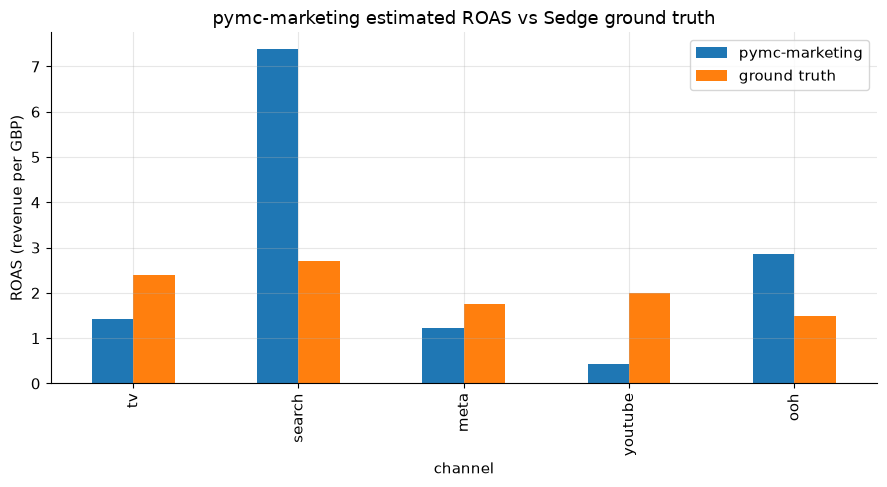

In [6]:
ax = roas[["roas_pymc_marketing", "roas_ground_truth"]].plot.bar()
ax.set_ylabel("ROAS (revenue per GBP)")
ax.set_xlabel("channel")
ax.set_title("pymc-marketing estimated ROAS vs Sedge ground truth")
ax.legend(["pymc-marketing", "ground truth"])
ax.figure.tight_layout()

## How this compares to the from-scratch reference model

The labs build `reference_model` by hand: they adstock and saturate each channel with the transform functions from `mmm_book`, put HalfNormal priors on the betas, and write the PyMC model out line by line.
`pymc-marketing` expresses the same idea - carryover, diminishing returns, and a linear sum of channel contributions - but wraps the media transforms, the scaling, the contribution accounting, and the plotting behind a small API.

The two are the same model in spirit, not the same numbers.
They differ in the saturation family (a logistic curve here versus the Hill curve the generator used), in how inputs are scaled, in the default priors, and in what the labs fix at the truth (adstock alpha, Hill half and slope) while the library estimates it.
The sampler now runs cleanly, so the gaps in the table above are the model's, not the sampler's.
The library's ROAS is well away from the truth for most channels: it overstates Search and OOH and understates Television, Meta and YouTube.
Search is the clearest case, and it is the mistake of Chapter 35's first model: this bridge hands the library total Search spend, brand search included, and brand search follows demand rather than creating it.
A national fit also has far less variation to separate correlated channels than the regional case-study model, which is why Meta and YouTube are poorly split here.
That is the practical takeaway of a bridge: the library gets you a plausible-looking answer with far less plumbing, and knowing the internals, and having a synthetic truth to check against, is what lets you see when it is not yet a trustworthy one.

## Takeaway

Learn the internals first, then use the library in production.
Everything `pymc-marketing` did here - adstock, saturation, priors, sampling, contribution and ROAS accounting - is something the from-scratch labs taught you to build yourself.
Once you understand those pieces, a production library is a time saver you can reason about, not a black box you have to trust blindly.